# Neural tissue segmentation with manually annotated training data

This notebook is adapted from Code Example 5-1 of the *Deep Learning Crash Course* ([original notebook](https://github.com/DeepTrackAI/DeepLearningCrashCourse/blob/main/Ch05_UNet/ec05_1_unet/unet.ipynb)). It complements the [neural tissue segmentation tutorial](DTEx251_neural_tissue_segmentation.ipynb), where a U-Net is trained only on simulated images. Here, we train the same U-Net architecture directly on the manually annotated ssTEM images and evaluate it with the same metrics, so the results can serve as a reference for the simulation-based approach.

In [1]:
# !pip install deeplay deeptrack  # Uncomment if running on Colab/Kaggle.

## Loading the Dataset with Segmented Tissue Images

The dataset consists of 20 serial-section Transmission Electron Microscopy (ssTEM) images (1024 × 1024 pixels) of the ventral nerve cord of *Drosophila melanogaster*, the fruit fly, together with ground-truth segmentations. The dataset provides labels for two structures: the neuronal intracellular regions and the mitochondria. As a simplification, we treat everything else as a third class, and since these regions are dominated by the cell membranes, we will refer to the three channels as membrane, intracellular, and mitochondria.

Download the dataset ...

In [2]:
import os

if not os.path.exists("tissue_images_dataset"):
    os.system("git clone https://github.com/DeepTrackAI/tissue_images_dataset")

raw_path = os.path.join("tissue_images_dataset", "stack1", "raw")
seg_path = os.path.join("tissue_images_dataset", "stack1", "labels")

... create the sources to manage the images during training ...

In [3]:
import deeptrack as dt

raw_paths = dt.sources.ImageFolder(root=raw_path)
seg_paths = dt.sources.ImageFolder(root=seg_path)
paths = dt.sources.Source(raw=raw_paths, label=seg_paths)
train_paths, val_paths, test_paths = \
    dt.sources.random_split(paths, [0.8, 0.1, 0.1])

train_srcs = train_paths.product(flip_ud=[True, False], flip_lr=[True, False])
val_srcs = val_paths.constants(flip_ud=False, flip_lr=False)
test_srcs = test_paths.constants(flip_ud=False, flip_lr=False)

sources = dt.sources.Join(train_srcs, val_srcs, test_srcs)

... check how many images are loaded.

In [4]:
print(f"Raw images: {len(raw_paths)}")
print(f"Segmentation labels: {len(seg_paths)}")

Raw images: 20
Segmentation labels: 20


## Creating the Data Pipelines

Implement a function to filter the labels in the segmentation map ...

In [5]:
import numpy as np

def select_labels(class_labels):
    """Create a function to filter and remap labels in a segmentation map."""
    def inner(segmentation):
        seg = segmentation.copy()
        mask = seg * np.isin(seg, class_labels).astype(np.uint8)
        new_seg = (np.select([mask == c for c in class_labels],
                             np.arange(len(class_labels)) + 1)
                   .astype(np.uint8).squeeze())
        one_hot_encoded_seg = np.eye(len(class_labels) + 1)[new_seg]
        return one_hot_encoded_seg        
    return inner

... define the pipelines ...

In [6]:
import torch

im_pip = dt.LoadImage(sources.raw.path) >> dt.NormalizeMinMax()
seg_pip = (dt.LoadImage(sources.label.path)
           >> dt.Lambda(select_labels, class_labels=[255, 191]))
pip = ((im_pip & seg_pip) >> dt.FlipLR(sources.flip_lr)
       >> dt.FlipUD(sources.flip_ud) >> dt.MoveAxis(2, 0)
       >> dt.pytorch.ToTensor(dtype=torch.float))

... define the training and validation datasets ...

In [7]:
train_dataset = dt.pytorch.Dataset(pip, train_srcs)
val_dataset = dt.pytorch.Dataset(pip, val_srcs)

... and plot the input image and corresponding ground-truth segmentation.

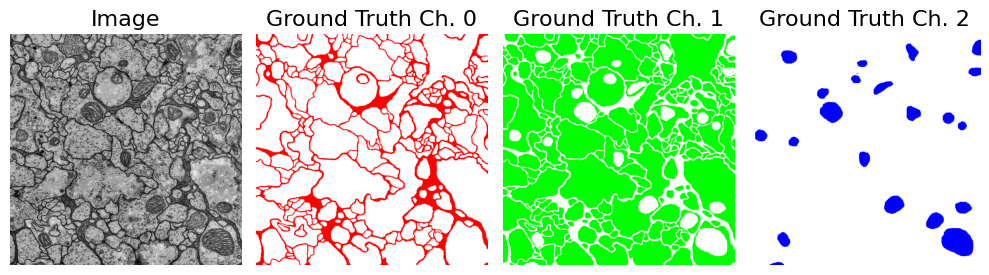

In [8]:
import matplotlib.pyplot as plt

image, segmentation = train_dataset[0]

fig, axs = plt.subplots(1, 4, figsize=(10, 5))

axs[0].imshow(image.permute(1, 2, 0), cmap="gray")
axs[0].set_title("Image", fontsize=16)
axs[0].set_axis_off()

for i in range(segmentation.shape[0]):
    segmentation_color = torch.ones_like(segmentation)
    for j in range(segmentation.shape[0]):
        if j != i: segmentation_color[j, ...] = 1 - segmentation[i, ...]
    axs[i + 1].imshow(segmentation_color.permute(1, 2, 0))
    axs[i + 1].set_title(f"Ground Truth Ch. {i}", fontsize=16)
    axs[i + 1].set_axis_off()

plt.tight_layout()
plt.show()

## Defining and Training the U-Net

Define a class to compute Jaccard Index for multi-class predictions after taking the
channel with the maximum value ...

In [9]:
from torchmetrics.classification import MulticlassJaccardIndex

class ArgmaxJI(MulticlassJaccardIndex):
    """Compute Jaccard Index for multi-class predictions after argmax."""

    def update(self, preds, targets):
        """Update Jaccard Index using argmax of class predictions."""
        super().update(preds.argmax(dim=1), targets.argmax(dim=1))

... define and create the U-Net ...

In [10]:
import deeplay as dl

ji_metric = ArgmaxJI(num_classes=3)
ji_metric_per_class = ArgmaxJI(num_classes=3, average=None)

unet = dl.UNet2d(
    in_channels=1, channels=[16, 32, 64, 128, 256], out_channels=3, skip=dl.Cat(),
)
unet_reg_template = dl.Regressor(
    model=unet, loss=torch.nn.CrossEntropyLoss(), metrics=[ji_metric],
    optimizer=dl.Adam(),
)
unet_reg = unet_reg_template.create()

print(unet_reg)

Regressor(
  (loss): CrossEntropyLoss()
  (optimizer): Adam[Adam]()
  (train_metrics): MetricCollection(
    (ArgmaxJI): ArgmaxJI(),
    prefix=train
  )
  (val_metrics): MetricCollection(
    (ArgmaxJI): ArgmaxJI(),
    prefix=val
  )
  (test_metrics): MetricCollection(
    (ArgmaxJI): ArgmaxJI(),
    prefix=test
  )
  (model): UNet2d(
    (encoder): ConvolutionalEncoder2d(
      (blocks): LayerList(
        (0): Conv2dBlock(
          (layer): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (activation): ReLU()
        )
        (1): Conv2dBlock(
          (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
          (layer): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (activation): ReLU()
        )
        (2): Conv2dBlock(
          (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
          (layer): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1,

... define the training and validation data loaders.

In [11]:
train_loader = dl.DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = dl.DataLoader(val_dataset, batch_size=2)

We train with early stopping: training continues until the validation Jaccard Index stops improving (patience of 30 epochs), up to 300 epochs, and the best checkpoint is saved along the way.

In [12]:
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

early_stopping = EarlyStopping(
    monitor="valArgmaxJI_epoch", mode="max", patience=30
)
logger = CSVLogger("lightning_logs", name="train_until_stagnation")
checkpoint = ModelCheckpoint(
    monitor="valArgmaxJI_epoch", mode="max", save_top_k=1
)

trainer = dl.Trainer(
    max_epochs=300,
    logger=logger,
    callbacks=[early_stopping, checkpoint],
    accelerator="auto",
)
trainer.fit(unet_reg, train_loader, val_loader)

Missing logger folder: lightning_logs\train_until_stagnation

  | Name          | Type             | Params
---------------------------------------------------
0 | loss          | CrossEntropyLoss | 0     
1 | train_metrics | MetricCollection | 0     
2 | val_metrics   | MetricCollection | 0     
3 | test_metrics  | MetricCollection | 0     
4 | model         | UNet2d           | 2.1 M 
5 | optimizer     | Adam             | 0     
---------------------------------------------------
2.1 M     Trainable params
0         Non-trainable params
2.1 M     Total params
8.466     Total estimated model params size (MB)


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

C:\Users\xgrmir\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:441: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
C:\Users\xgrmir\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
C:\Users\xgrmir\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\lightning\pytorch\loops\fit_loop.py:298: The number of tra

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (91 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... plot the training and validation metrics with early stopping ...

In [13]:
def plot_training_metrics(m):
    """Plot training metrics by epoch."""
    fig, axs = plt.subplots(2, figsize=(6, 4))

    axs[0].plot(m["epoch"], m["train_loss_epoch"], label="Train Loss")
    axs[0].plot(m["epoch"], m["val_loss_epoch"], label="Validation Loss")
    axs[0].set_xlabel("Epoch")
    axs[0].set_ylabel("Loss")
    axs[0].legend()

    axs[1].plot(m["epoch"], m["trainArgmaxJI_epoch"], label="Train JI")
    axs[1].plot(m["epoch"], m["valArgmaxJI_epoch"], label="Validation JI")
    axs[1].set_xlabel("Epoch")
    axs[1].set_ylabel("Jaccard Index (JI)")
    axs[1].legend()

    plt.tight_layout()
    plt.show()

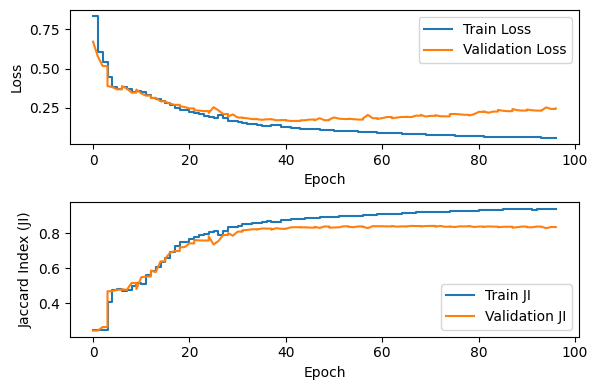

In [14]:
import pandas as pd

metrics = pd.read_csv(
    os.path.join(logger.log_dir, "metrics.csv")
).ffill()

plot_training_metrics(metrics)

## Evaluating the Trained U-Net

We load the best checkpoint and run it on the test images, which the network did not see during training.

In [15]:
best_ckpt_path = checkpoint.best_model_path
best_unet_reg = dl.Regressor.load_from_checkpoint(best_ckpt_path)

In [16]:
test_dataset = dt.pytorch.Dataset(pip, test_srcs)
test_loader = dl.DataLoader(test_dataset, batch_size=2, shuffle=False)

pred_seg = torch.cat(trainer.predict(best_unet_reg, test_loader), dim=0)

C:\Users\xgrmir\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:441: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

In [17]:
from matplotlib.colors import ListedColormap

channel_colors = [
    (0 / 255, 88 / 255, 160 / 255),     # membrane      - blue
    (81 / 255, 164 / 255, 81 / 255),    # intracellular - green
    (241 / 255, 154 / 255, 71 / 255),   # mitochondria  - orange
]

# Colormap for the argmax plots: the intracellular (background) class is shown
# white so the membrane and mitochondria stand out.
seg_cmap = ListedColormap([channel_colors[0], (1, 1, 1), channel_colors[2]])

We measure how well the predictions match the ground truth using the Jaccard Index and the Dice score. Looping over the test images, we compute the score for each and report both the overall average and the average per class (membrane, intracellular region, and mitochondria). The two measures are computed from the same true positives, false positives, and false negatives, so the Dice score follows directly from the Jaccard index.

In [18]:
ji_metric.reset()
ji_metric_per_class.reset()

ji = np.zeros(len(test_dataset))
ji_per_class = torch.zeros((len(test_dataset), 3))

for sample in range(len(test_dataset)):
    test_image, test_seg = test_dataset[sample]
    ji_sample = ji_metric(
        pred_seg[sample].unsqueeze(0), test_seg.unsqueeze(0)
    )
    ji[sample] = ji_sample

    ji_sample_per_class = ji_metric_per_class(
        pred_seg[sample].unsqueeze(0), test_seg.unsqueeze(0)
    )
    ji_per_class[sample, :] = ji_sample_per_class

# The Dice score follows from the Jaccard index, since both are computed
# from the same true positives, false positives and false negatives.
dice_per_class = 2 * ji_per_class / (1 + ji_per_class)
dice = dice_per_class.mean(dim=1).numpy()


print(
    f"average jaccard index: {np.mean(ji):.3f}, \n"
    f"average jaccard index per class: \n"
    f"  membrane: {torch.mean(ji_per_class, dim=0)[0]:.3f}\n"
    f"  intracellular: {torch.mean(ji_per_class, dim=0)[1]:.3f}\n"
    f"  mitochondria: {torch.mean(ji_per_class, dim=0)[2]:.3f}\n\n"
    f"average dice score: {np.mean(dice):.3f}, \n"
    f"average dice score per class: \n"
    f"  membrane: {torch.mean(dice_per_class, dim=0)[0]:.3f}\n"
    f"  intracellular: {torch.mean(dice_per_class, dim=0)[1]:.3f}\n"
    f"  mitochondria: {torch.mean(dice_per_class, dim=0)[2]:.3f}"
)

average jaccard index: 0.826, 
average jaccard index per class: 
  membrane: 0.761
  intracellular: 0.916
  mitochondria: 0.800

average dice score: 0.903, 
average dice score per class: 
  membrane: 0.864
  intracellular: 0.956
  mitochondria: 0.889


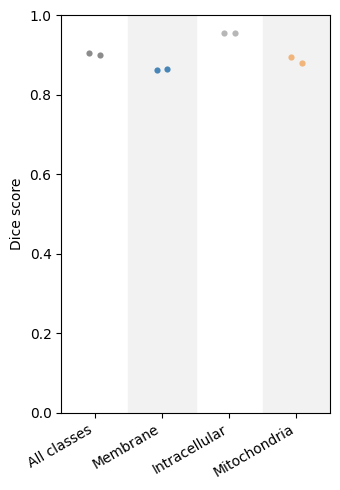

In [19]:
scores = {
    "All classes": (dice, "#5c5c5cff"),
    "Membrane": (dice_per_class[:, 0], channel_colors[0]),
    "Intracellular": (dice_per_class[:, 1], "#999999ff"),
    "Mitochondria": (dice_per_class[:, 2], channel_colors[2]),
}

fig, ax = plt.subplots(figsize=(3.5, 5))

# The test set has only two images, too few for a box plot to be meaningful,
# so we show the score of each test image as a point instead.
for m, (values, color) in enumerate(scores.values()):
    x = m + np.linspace(-0.08, 0.08, len(values))
    ax.scatter(x, values, s=20, alpha=0.7, color=color, linewidths=0)

for m in range(1, len(scores), 2):
    ax.axvspan(m - 0.5, m + 0.5, color="0.95", zorder=0)

ax.set_xticks(range(len(scores)), list(scores), rotation=30, ha="right")
ax.set_xlim(-0.5, len(scores) - 0.5)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Dice score")

fig.tight_layout()
plt.show()

To inspect the segmentation qualitatively, we show the image next to the ground-truth segmentation and the model's prediction for the best-scoring test image.

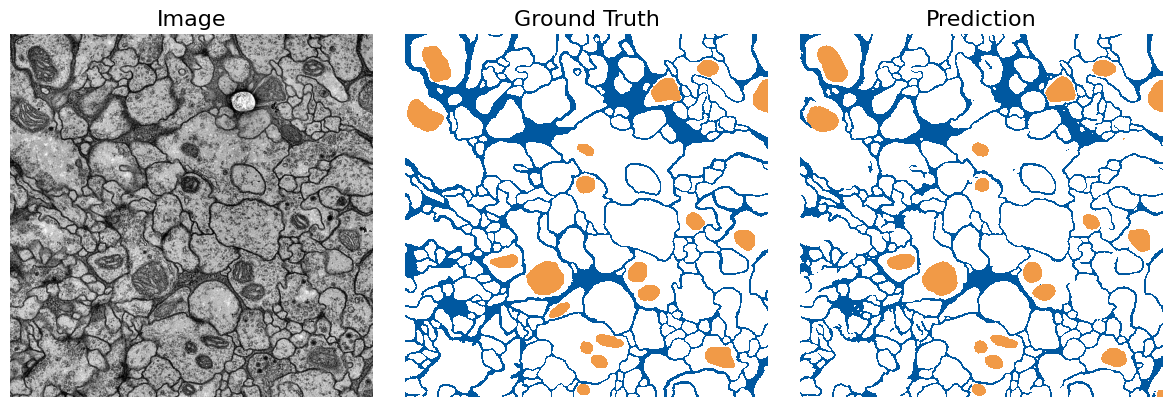

In [20]:
best_sample = int(np.argmax(ji))
test_image, test_seg = test_dataset[best_sample]

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(test_image[0], cmap="gray")
axs[0].set_title("Image", fontsize=16)
axs[0].axis("off")

axs[1].imshow(test_seg.argmax(dim=0), cmap=seg_cmap, interpolation="nearest")
axs[1].set_title("Ground Truth", fontsize=16)
axs[1].axis("off")

axs[2].imshow(
    pred_seg[best_sample].argmax(dim=0),
    cmap=seg_cmap,
    interpolation="nearest",
)
axs[2].set_title("Prediction", fontsize=16)
axs[2].axis("off")

plt.tight_layout()
plt.show()